In [51]:
# import libraries

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [5]:
# Load the CSV into a DataFrame
df = pd.read_csv(r"C:\Users\Admin\1_Georgia Tech\Sim 6414\Project start\RealtimeWeatherReadingsacrossSingapore\Historical 24-hour Weather Forecast (2024).csv")

# Preview the first 5 rows
print(df.head())

         date                  timestamp           update_timestamp  \
0  2024-01-01  2024-01-01T05:31:00+08:00  2024-01-01T05:34:39+08:00   
1  2024-01-01  2024-01-01T05:31:00+08:00  2024-01-01T05:34:39+08:00   
2  2024-01-01  2024-01-01T05:31:00+08:00  2024-01-01T05:34:39+08:00   
3  2024-01-01  2024-01-01T11:52:00+08:00  2024-01-01T12:04:30+08:00   
4  2024-01-01  2024-01-01T11:52:00+08:00  2024-01-01T12:04:30+08:00   

   wind_speed_high  wind_speed_low wind_speed_direction     forecast_text  \
0             20.0            10.0                  NNE  Thundery Showers   
1             20.0            10.0                  NNE  Thundery Showers   
2             20.0            10.0                  NNE  Thundery Showers   
3             20.0            10.0                  NNE  Thundery Showers   
4             20.0            10.0                  NNE  Thundery Showers   

  forecast_code  relative_humidity_high  relative_humidity_low  ...  \
0            TL                    95.0

In [6]:
df.head()

,date,timestamp,update_timestamp,wind_speed_high,wind_speed_low,wind_speed_direction,forecast_text,forecast_code,relative_humidity_high,relative_humidity_low,...,south_forecast_text,south_forecast_code,north_forecast_text,north_forecast_code,east_forecast_text,east_forecast_code,central_forecast_text,central_forecast_code,west_forecast_text,west_forecast_code
0,2024-01-01,2024-01-01T05:31:00+08:00,2024-01-01T05:34:39+08:00,20.0,10.0,NNE,Thundery Showers,TL,95.0,65.0,...,Showers,SH,Showers,SH,Showers,SH,Showers,SH,Showers,SH
1,2024-01-01,2024-01-01T05:31:00+08:00,2024-01-01T05:34:39+08:00,20.0,10.0,NNE,Thundery Showers,TL,95.0,65.0,...,Thundery Showers,TL,Thundery Showers,TL,Thundery Showers,TL,Thundery Showers,TL,Thundery Showers,TL
2,2024-01-01,2024-01-01T05:31:00+08:00,2024-01-01T05:34:39+08:00,20.0,10.0,NNE,Thundery Showers,TL,95.0,65.0,...,Light Rain,LR,Light Rain,LR,Light Rain,LR,Light Rain,LR,Light Rain,LR
3,2024-01-01,2024-01-01T11:52:00+08:00,2024-01-01T12:04:30+08:00,20.0,10.0,NNE,Thundery Showers,TL,95.0,65.0,...,Thundery Showers,TL,Thundery Showers,TL,Thundery Showers,TL,Thundery Showers,TL,Thundery Showers,TL
4,2024-01-01,2024-01-01T11:52:00+08:00,2024-01-01T12:04:30+08:00,20.0,10.0,NNE,Thundery Showers,TL,95.0,65.0,...,Cloudy,CL,Cloudy,CL,Cloudy,CL,Cloudy,CL,Cloudy,CL


In [7]:
df['forecast_text'].value_counts()

forecast_text
Thundery Showers                           6711
Showers                                     775
Partly Cloudy (Day)                         559
Cloudy                                      303
Windy                                       222
Light Rain                                  193
Moderate Rain                               171
Passing Showers                             165
Fair & Warm                                 120
Fair (Day)                                   93
Heavy Thundery Showers                       15
Heavy Thundery Showers with Gusty Winds       9
Name: count, dtype: int64

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9336 entries, 0 to 9335
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    9336 non-null   object 
 1   timestamp               9336 non-null   object 
 2   update_timestamp        9336 non-null   object 
 3   wind_speed_high         9336 non-null   float64
 4   wind_speed_low          9336 non-null   float64
 5   wind_speed_direction    9336 non-null   object 
 6   forecast_text           9336 non-null   object 
 7   forecast_code           9336 non-null   object 
 8   relative_humidity_high  9336 non-null   float64
 9   relative_humidity_low   9336 non-null   float64
 10  valid_period_text       9336 non-null   object 
 11  valid_period_start      9336 non-null   object 
 12  valid_period_end        9336 non-null   object 
 13  temperature_high        9336 non-null   float64
 14  temperature_low         9336 non-null   

In [9]:
df['date'].value_counts()

date
2024-12-30    74
2024-12-24    57
2024-06-21    54
2024-12-12    54
2024-06-19    53
              ..
2024-03-14    13
2024-12-08     9
2024-02-28     8
2024-03-06     3
2024-03-08     3
Name: count, Length: 357, dtype: int64

In [10]:
# note to self focus on date. forecast_text, temperature_high, temperature_low.

# there are 29 days from 2024 01-06 to 30-06, and 30 days from 2024 01-12 to 31-12

### Timestamp and columns of interest

In [11]:
df_columns_interest = df[['date', 'timestamp', 'forecast_text','temperature_high','temperature_low']]

In [12]:
work_df = df_columns_interest.copy()

In [13]:
work_df['timestamp'] = pd.to_datetime(work_df['timestamp']).dt.tz_localize(None)

# googled this online, df['timestamp'] = pd.to_datetime(df['timestamp']).dt.tz_localize(None)

In [14]:
work_df = work_df.drop_duplicates(subset=['timestamp'], keep='first')

#  googled this online, df = df.drop_duplicates(subset=['timestamp'], keep='first')

### start to filter

In [15]:
june_df = work_df.query("'2024-06-01' <= date <= '2024-06-30'") # only up to 30 days
dec_df = work_df.query("'2024-12-01' <= date <= '2024-12-31'")

In [16]:
june_df_sort = june_df.sort_values(by="timestamp").reset_index(drop = True)
dec_df_sort = dec_df.sort_values(by="timestamp").reset_index(drop = True)


In [17]:
june_df_sort.head(60)

,date,timestamp,forecast_text,temperature_high,temperature_low
0,2024-06-01,2024-06-01 03:22:00,Thundery Showers,34.0,25.0
1,2024-06-01,2024-06-01 04:28:00,Thundery Showers,34.0,25.0
2,2024-06-01,2024-06-01 05:19:00,Thundery Showers,34.0,25.0
3,2024-06-01,2024-06-01 05:37:00,Thundery Showers,34.0,25.0
4,2024-06-01,2024-06-01 07:33:00,Thundery Showers,32.0,24.0
5,2024-06-01,2024-06-01 08:17:00,Thundery Showers,31.0,24.0
6,2024-06-01,2024-06-01 11:05:00,Thundery Showers,30.0,23.0
7,2024-06-01,2024-06-01 11:40:00,Moderate Rain,30.0,23.0
8,2024-06-01,2024-06-01 15:35:00,Cloudy,30.0,23.0
9,2024-06-01,2024-06-01 17:36:00,Thundery Showers,34.0,24.0


In [18]:
june_df_sort

,date,timestamp,forecast_text,temperature_high,temperature_low
0,2024-06-01,2024-06-01 03:22:00,Thundery Showers,34.0,25.0
1,2024-06-01,2024-06-01 04:28:00,Thundery Showers,34.0,25.0
2,2024-06-01,2024-06-01 05:19:00,Thundery Showers,34.0,25.0
3,2024-06-01,2024-06-01 05:37:00,Thundery Showers,34.0,25.0
4,2024-06-01,2024-06-01 07:33:00,Thundery Showers,32.0,24.0
...,...,...,...,...,...
270,2024-06-30,2024-06-30 15:46:00,Cloudy,31.0,24.0
271,2024-06-30,2024-06-30 17:35:00,Thundery Showers,34.0,25.0
272,2024-06-30,2024-06-30 21:49:00,Thundery Showers,34.0,25.0
273,2024-06-30,2024-06-30 22:20:00,Thundery Showers,34.0,25.0


In [19]:
dec_df_sort

,date,timestamp,forecast_text,temperature_high,temperature_low
0,2024-12-01,2024-12-01 04:25:00,Thundery Showers,34.0,24.0
1,2024-12-01,2024-12-01 04:28:00,Thundery Showers,34.0,24.0
2,2024-12-01,2024-12-01 04:55:00,Thundery Showers,34.0,24.0
3,2024-12-01,2024-12-01 05:30:00,Thundery Showers,34.0,24.0
4,2024-12-01,2024-12-01 05:39:00,Thundery Showers,34.0,24.0
...,...,...,...,...,...
269,2024-12-31,2024-12-31 11:36:00,Thundery Showers,34.0,25.0
270,2024-12-31,2024-12-31 13:16:00,Thundery Showers,34.0,25.0
271,2024-12-31,2024-12-31 17:33:00,Thundery Showers,34.0,25.0
272,2024-12-31,2024-12-31 19:47:00,Thundery Showers,34.0,25.0


In [20]:
june_df.value_counts(ascending=False)

date        timestamp            forecast_text     temperature_high  temperature_low
2024-06-01  2024-06-01 03:22:00  Thundery Showers  34.0              25.0               1
            2024-06-01 04:28:00  Thundery Showers  34.0              25.0               1
            2024-06-01 05:19:00  Thundery Showers  34.0              25.0               1
            2024-06-01 05:37:00  Thundery Showers  34.0              25.0               1
            2024-06-01 07:33:00  Thundery Showers  32.0              24.0               1
                                                                                       ..
2024-06-30  2024-06-30 15:46:00  Cloudy            31.0              24.0               1
            2024-06-30 17:35:00  Thundery Showers  34.0              25.0               1
            2024-06-30 21:49:00  Thundery Showers  34.0              25.0               1
            2024-06-30 22:20:00  Thundery Showers  34.0              25.0               1
            202

### understand type of weather_type and also create column for rain type e.g. no rain

In [21]:
june_df_sort['forecast_text'].value_counts()

forecast_text
Thundery Showers       226
Cloudy                  10
Light Rain              10
Showers                  8
Partly Cloudy (Day)      8
Moderate Rain            7
Windy                    6
Name: count, dtype: int64

In [22]:
dec_df_sort['forecast_text'].value_counts()

forecast_text
Thundery Showers       200
Light Rain              20
Showers                 18
Partly Cloudy (Day)     16
Cloudy                   9
Moderate Rain            6
Windy                    4
Passing Showers          1
Name: count, dtype: int64

In [23]:
def weather_type(df):
  if df['forecast_text'] == 'Thundery Showers': # note to self - chances of ppl buying lemonade is the lowest
    return 'Bad Weather'
  elif df['forecast_text'] in ['Light Rain', 'Showers', 'Moderate Rain']: # note to self - chances of ppl buying lemonade is the medium
    return 'Not optimal Weather'
  else: # note to self - chances of ppl buying lemonade is the highest
    return 'Ok weather' 


# Apply - create the 'condition' column
june_df_sort['condition'] = june_df_sort.apply(weather_type, axis=1)
dec_df_sort['condition'] = dec_df_sort.apply(weather_type, axis=1)

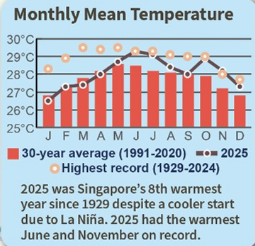

# use this as reference for temperature
https://www.nea.gov.sg/media/news/news/index/spore-records-wettest-ever-march-and-hottest-ever-june-and-november-in-2025

### as noted June Mean temperature is 29 c, and December Mean temperature is 27.5c

In [59]:
## so if the temperature if it is above 29 celsius people are more likely to purchase lemonade 
TEMP_THRESHOLD = 29
HOT_MULTIPLIER = 1.25

In [24]:
june_df_sort['temp_mid'] = (june_df_sort['temperature_high'] + june_df_sort['temperature_low']) / 2
dec_df_sort['temp_mid']  = (dec_df_sort['temperature_high']  + dec_df_sort['temperature_low'])  / 2

temps_mid = {
    'June':     june_df_sort['temp_mid'].values,
    'December': dec_df_sort['temp_mid'].values,
}

In [25]:
## create new column that average each of the temperature so you get a new column that contains 

In [26]:
def temperature_type(df):
    df['temp_category'] = 'NOT HOT'
    if df['temp_mid'] >= 29.0:
        return 'HOT'
    else:
        return 'NOT HOT'


In [27]:
june_df_sort['temp_category'] = june_df_sort.apply(temperature_type, axis=1)
dec_df_sort['temp_category'] = dec_df_sort.apply(temperature_type, axis=1)

In [28]:
june_df_sort

,date,timestamp,forecast_text,temperature_high,temperature_low,condition,temp_mid,temp_category
0,2024-06-01,2024-06-01 03:22:00,Thundery Showers,34.0,25.0,Bad Weather,29.5,HOT
1,2024-06-01,2024-06-01 04:28:00,Thundery Showers,34.0,25.0,Bad Weather,29.5,HOT
2,2024-06-01,2024-06-01 05:19:00,Thundery Showers,34.0,25.0,Bad Weather,29.5,HOT
3,2024-06-01,2024-06-01 05:37:00,Thundery Showers,34.0,25.0,Bad Weather,29.5,HOT
4,2024-06-01,2024-06-01 07:33:00,Thundery Showers,32.0,24.0,Bad Weather,28.0,NOT HOT
...,...,...,...,...,...,...,...,...
270,2024-06-30,2024-06-30 15:46:00,Cloudy,31.0,24.0,Ok weather,27.5,NOT HOT
271,2024-06-30,2024-06-30 17:35:00,Thundery Showers,34.0,25.0,Bad Weather,29.5,HOT
272,2024-06-30,2024-06-30 21:49:00,Thundery Showers,34.0,25.0,Bad Weather,29.5,HOT
273,2024-06-30,2024-06-30 22:20:00,Thundery Showers,34.0,25.0,Bad Weather,29.5,HOT


In [29]:
dec_df_sort

,date,timestamp,forecast_text,temperature_high,temperature_low,condition,temp_mid,temp_category
0,2024-12-01,2024-12-01 04:25:00,Thundery Showers,34.0,24.0,Bad Weather,29.0,HOT
1,2024-12-01,2024-12-01 04:28:00,Thundery Showers,34.0,24.0,Bad Weather,29.0,HOT
2,2024-12-01,2024-12-01 04:55:00,Thundery Showers,34.0,24.0,Bad Weather,29.0,HOT
3,2024-12-01,2024-12-01 05:30:00,Thundery Showers,34.0,24.0,Bad Weather,29.0,HOT
4,2024-12-01,2024-12-01 05:39:00,Thundery Showers,34.0,24.0,Bad Weather,29.0,HOT
...,...,...,...,...,...,...,...,...
269,2024-12-31,2024-12-31 11:36:00,Thundery Showers,34.0,25.0,Bad Weather,29.5,HOT
270,2024-12-31,2024-12-31 13:16:00,Thundery Showers,34.0,25.0,Bad Weather,29.5,HOT
271,2024-12-31,2024-12-31 17:33:00,Thundery Showers,34.0,25.0,Bad Weather,29.5,HOT
272,2024-12-31,2024-12-31 19:47:00,Thundery Showers,34.0,25.0,Bad Weather,29.5,HOT


In [39]:
# June should have 30 days and December 31 days - for marker reference
print("June number of days:", june_df['date'].nunique())
print("December number of days:", dec_df['date'].nunique())

June number of days: 30
December number of days: 31


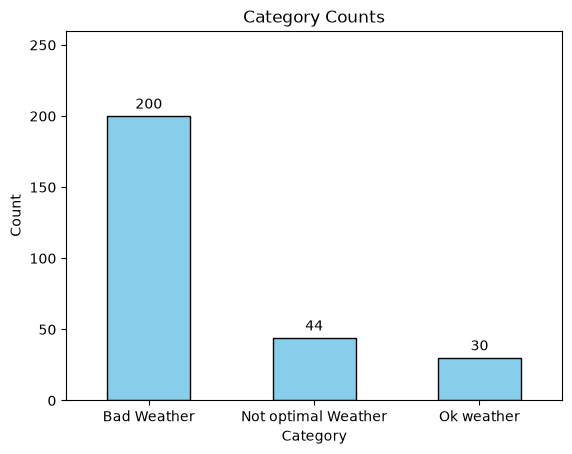

In [31]:
# Count occurrences and plot
dec_df_sort['condition'].value_counts().plot(kind='bar', color='skyblue')
# 1. Count occurrences and plot
ax = dec_df_sort["condition"].value_counts().plot(kind="bar", color="skyblue", edgecolor="black")

# 2. Add the exact numbers on top of each bar
ax.bar_label(ax.containers[0], padding=3)

# 3. Formatting
plt.title("Category Counts")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=0)  # Keeps x-axis labels horizontal
plt.ylim(0, june_df_sort["condition"].value_counts().max() * 1.15)  # Adds headroom for labels
plt.show()

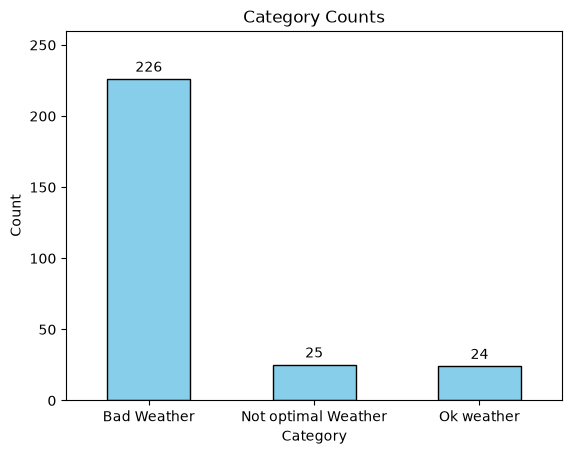

In [32]:
# Count occurrences and plot
june_df_sort['condition'].value_counts().plot(kind='bar', color='skyblue')
# 1. Count occurrences and plot
ax = june_df_sort["condition"].value_counts().plot(kind="bar", color="skyblue", edgecolor="black")

# 2. Add the exact numbers on top of each bar
ax.bar_label(ax.containers[0], padding=3)

# 3. Formatting
plt.title("Category Counts")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=0)  # Keeps x-axis labels horizontal
plt.ylim(0, june_df_sort["condition"].value_counts().max() * 1.15)  # Adds headroom for labels
plt.show()

##### for reference

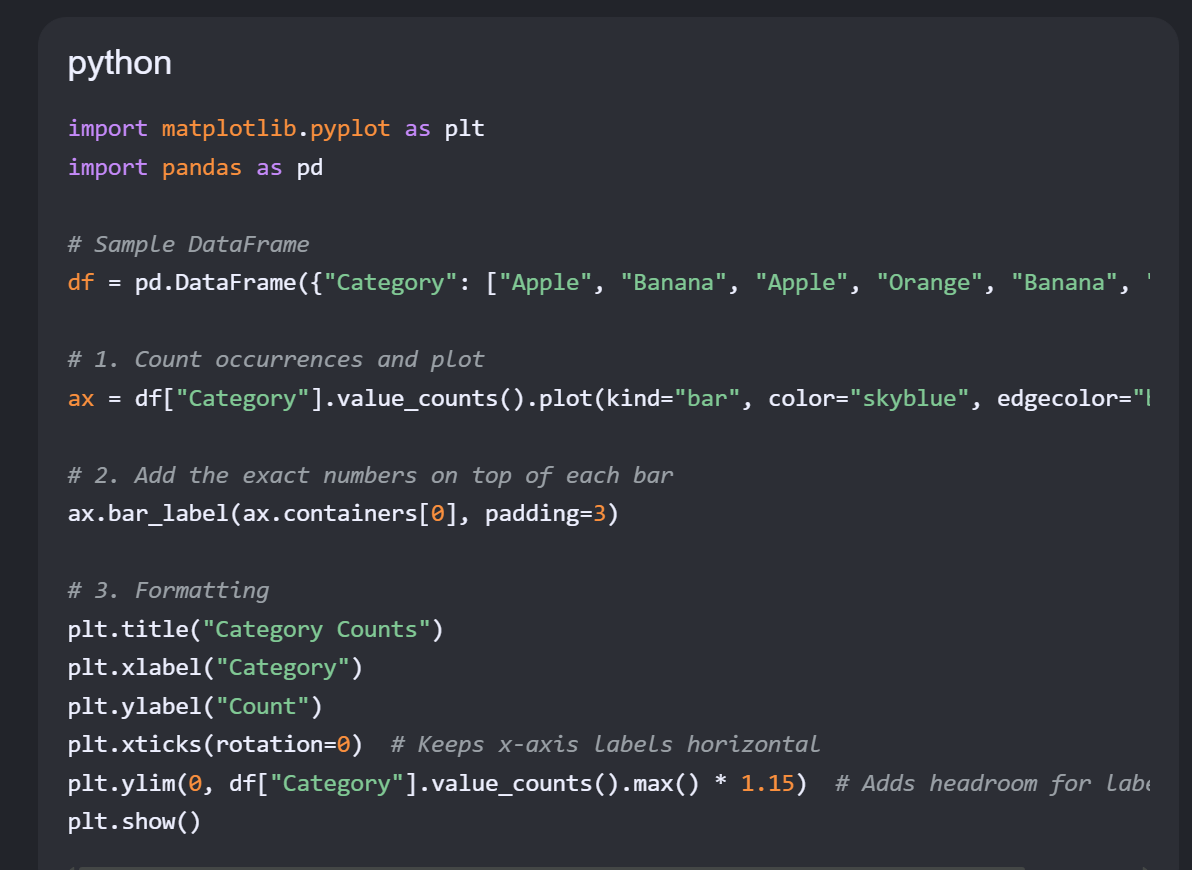

### Summarised from lecture notes

Cost ($c$): The wholesale unit cost paid to the supplier to acquire each item.

Price ($p$): The retail selling price charged to customers for each unit sold.

Salvage Value ($s$): The residual or liquidation value received for each leftover, unsold item at the end of the selling period (e.g., selling unsold newspapers to a pet store or discount buyer)

In [33]:
## newspaper model 
# Cost per cup from supermarket prices - refer to the word document
# recipe is based on https://www.acouplecooks.com/lemon-iced-tea/

c_sugar = 0.023 # 1 kg of sugar, divide by 1000
c_lemon = 0.105  # 1 kg of lemon, divide by 1000
c_ice   = 0.107 # 1 kg of ice, divide by 1000
c_cup   = 0.0738   
cost = c_sugar + c_lemon + c_ice + c_cup

# Salvage per cup - AI generated to get a salvage cost, given that I don't have experience running a lemonade stand. 
# Gave LLM what is likely the salvage cost, and shown
s_sugar = min(0.053, c_sugar)   # capped at cost
s_lemon = 0.075                 # YOUR TURN: replace with a sourced value (draft says AI-generated, which must be disclosed)
salvage_value = s_sugar + s_lemon           # ice melts follow the lemonade tycoon game, ice melt because I dont want to include the calculation of electricity etc. 



c = 0.2348   s = 0.0975   p = 3.15   CR = 0.9550


## 

Marginal Costs of Under- and Over-OrderingUsing cost, price, and salvage value, the model balances two financial risks.

Underage Cost ($c_u$): The opportunity cost or lost profit of underestimating demand (running out of stock).
$$\mathbf{c_u = p - c} \quad \text{(Retail Price minus Unit Cost)}$$
Overage Cost ($c_o$): The marginal loss incurred by overestimating demand (buying items that fail to sell).
$$\mathbf{c_o = c - s} \quad \text{(Unit Cost minus Salvage Value)}$$

The Critical Ratio (Critical Fractile)

The critical ratio (also called the critical fractile) calculates the target cumulative probability level that balances these two risk costs to maximize expected profit

$$\mathbf{\text{Critical Ratio} = \frac{c_u}{c_u + c_o} = \frac{p - c}{(p - c) + (c - s)}}$$

In [40]:
# Price: midpoint of $2.50 to $3.80 range
price = (2.50 + 3.80) / 2

CR = (p - c) / (p - s)
print(f"c = {c:.4f}   s = {s:.4f}   p = {p:.2f}   CR = {CR:.4f}")

c = 0.2348   s = 0.0975   p = 3.15   CR = 0.9550


In [ ]:
# z score 

# =NORM.S.INV(0.9550) in excel results in 
z_score = 1.695398

#### included photo reference evidence
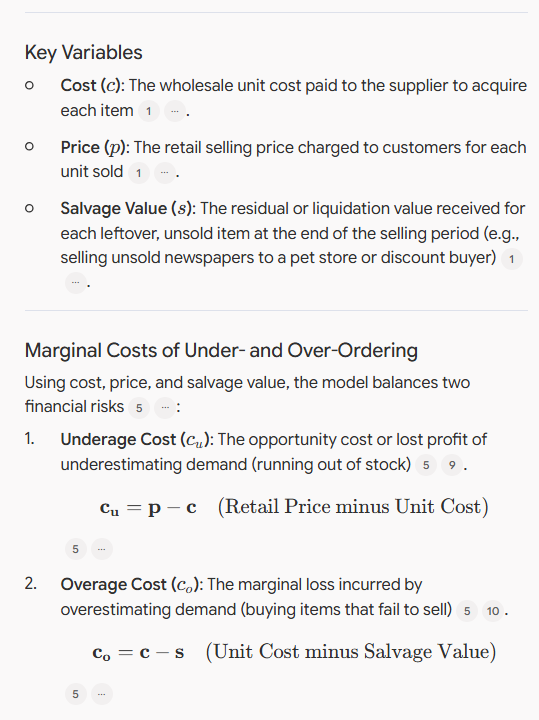
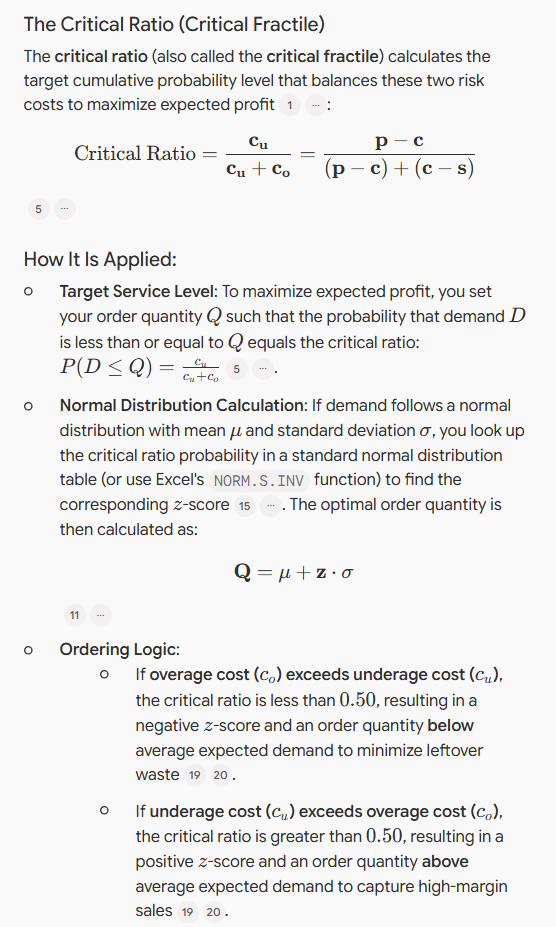

Analysis

## Optimal Quantity ($Q$)

$$Q = \mu + z \cdot \sigma$$

In [45]:
# note to self, q is the optimal quantity 
# u is the average demand 
# z is the z score
# Standard Deviation 

### to find variance

$$\text{Var}(X) = \frac{(a - b)^2 + (m - a)(m - b)}{18}$$

### To find standard deviation

$$\sigma = \sqrt{\text{Var}(X)} = \sqrt{\frac{a^2 + m^2 + b^2 - ab - am - bm}{18}}$$

### couldnt find any creditable sources to know how much drinks a store sells

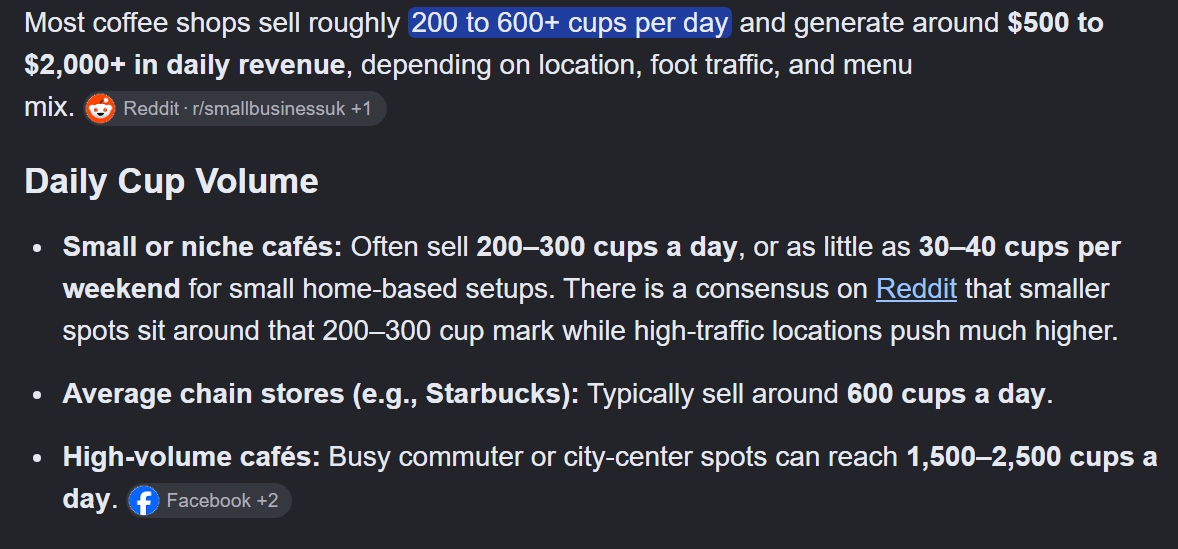

In [54]:
# cups per day, TRIA(min, mode, max)
demand_params = {
    'Ok weather':          (200, 250, 450), # Minimum demand = 200, Most Likely (Mode) = 250, Maximum demand = 450.
    'Not optimal Weather': (100, 150, 300), # Minimum demand = 100, Mode = 150, Max = 300.
    'Bad Weather':         (30, 50, 150),} # Minimum demand = 30, Mode = 50, Max = 150.

In [58]:
frames = []
for season, d in [('June', june_df_sort), ('December', dec_df_sort)]:
    # Get the earliest forecast for each day
    daily = d.sort_values('timestamp').groupby('date').first()
    
    # Calculate probabilities and ensure all expected conditions are included
    p = (
        daily['condition']
        .value_counts(normalize=True)
        .reindex(list(demand_params), fill_value=0)
    )
    
    frames.append(
        pd.DataFrame({
            'season': season,
            'condition': p.index,
            'probability': p.values
        })
    )

df_weather = pd.concat(frames, ignore_index=True)
df_weather


,season,condition,probability
0,June,Ok weather,0.066667
1,June,Not optimal Weather,0.033333
2,June,Bad Weather,0.900000
3,December,Ok weather,0.096774
4,December,Not optimal Weather,0.129032
5,December,Bad Weather,0.774194


In [60]:
CR = (price - cost) / (price - salvage_value)
rng = np.random.default_rng(42)
for season in ['June', 'December']:
    s = df_weather[df_weather.season == season].set_index('condition')
    probs = np.array([s.loc[c, 'probability'] for c in demand_params])
    k  = rng.choice(3, size=200_000, p=probs)              # weather code for each simulated day
    ab = np.array(list(demand_params.values()))[k]         # that day's (min, mode, max)
    d  = np.rint(rng.triangular(ab[:, 0], ab[:, 1], ab[:, 2]))
    print(season, np.quantile(d, CR, method='higher'))

NameError: name 'cost' is not defined